In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mymlr as mlr
from scipy import stats

### 1A

Importering af datasæt

In [23]:
df = pd.read_csv('data/cars.csv')
df.describe(percentiles=[]).T

,count,mean,std,min,50%,max
year,9694.0,2.001097e+03,1.107696e+01,1.980000e+03,2.002000e+03,2.018000e+03
product_id,9694.0,4.866750e+02,2.789975e+02,0.000000e+00,5.120000e+02,1.066000e+03
sales,9694.0,5.910339e+04,8.694025e+04,1.000000e+01,2.739400e+04,8.914820e+05
number_households,9694.0,1.072133e+08,1.393279e+07,8.078000e+07,1.093000e+08,1.275900e+08
price,9694.0,3.604769e+01,1.712656e+01,1.114478e+01,3.182023e+01,9.998639e+01
height,9694.0,6.094814e+01,8.411517e+00,4.350000e+01,5.770000e+01,1.075000e+02
footprint,9694.0,1.339263e+04,1.968915e+03,6.514540e+03,1.333006e+04,2.182186e+04
weight,9694.0,3.561211e+03,8.977655e+02,1.113000e+03,3.470500e+03,8.550000e+03
hp,9694.0,1.921820e+02,8.388244e+01,4.400000e+01,1.750000e+02,6.450000e+02
mpg,9694.0,2.093615e+01,6.583005e+00,1.000000e+01,1.900000e+01,5.000000e+01


In [24]:
df['const'] = 1
df['log_number_trims'] = np.log(df['number_trims'])


1A deskriptiv Analyse

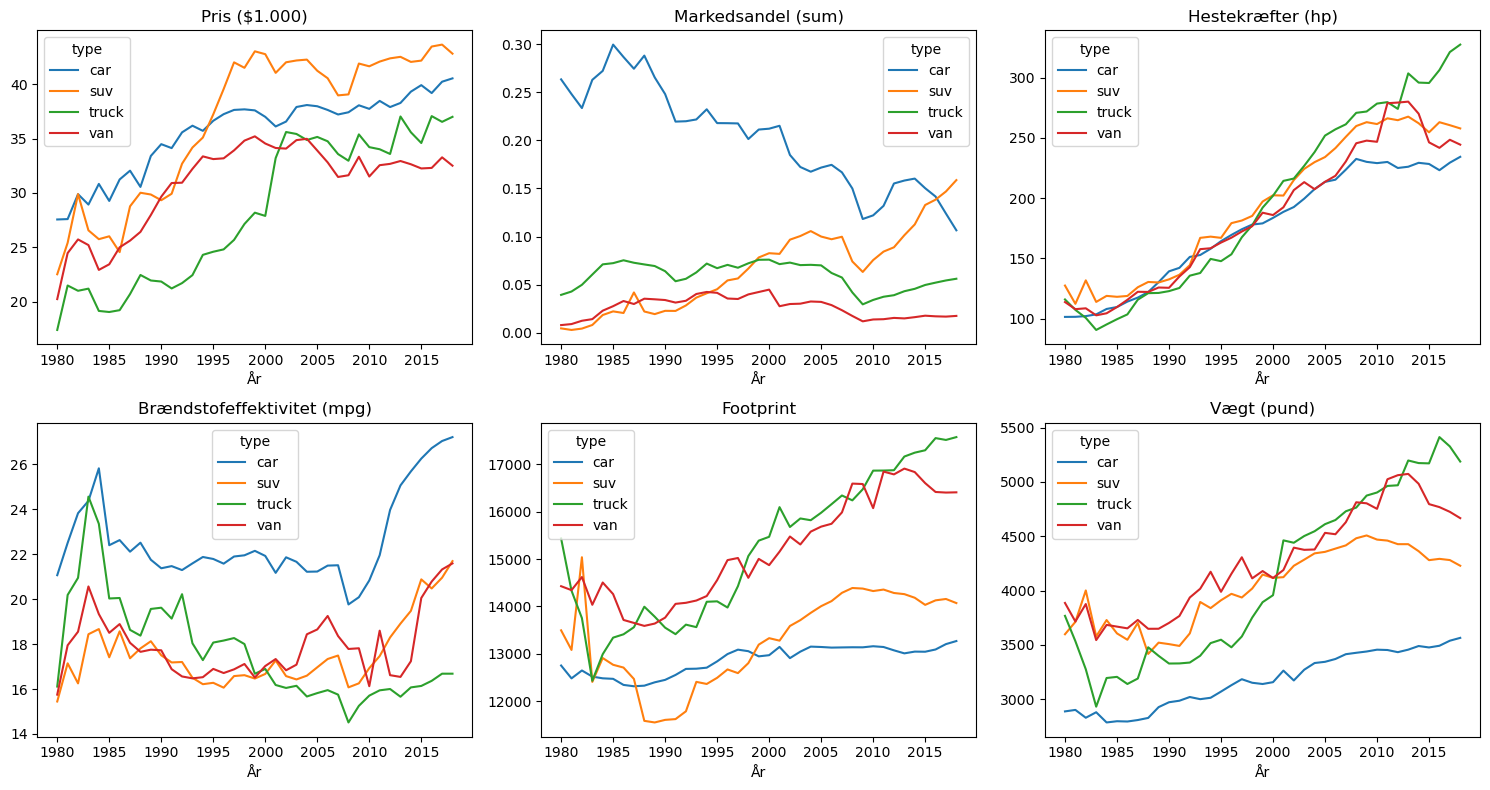

In [25]:
df['type'] = df[['car','suv','truck','van']].idxmax(axis=1)
types = ['car', 'suv', 'truck', 'van']

by = df.groupby(['year','type'])
panels = {
    'Pris ($1.000)': by['price'].mean().unstack(),
    'Markedsandel (sum)': by['market_share'].sum().unstack(),
    'Hestekræfter (hp)': by['hp'].mean().unstack(),
    'Brændstofeffektivitet (mpg)': by['mpg'].mean().unstack(),
    'Footprint': by['footprint'].mean().unstack(),
    'Vægt (pund)': by['weight'].mean().unstack(), 
}

fig, axes = plt.subplots(2,3,figsize=(15,8))
for ax, (title,data) in zip(axes.ravel(), panels.items()):
    data[types].plot(ax=ax)
    ax.set_title(title); ax.set_xlabel('År')
plt.tight_layout()
plt.show()

Sammenhæng mellem logaritmen af mardesandele relativt til andelen uden bil og bilpriser, samt mellem priser og fysiske attributter for bilerne.

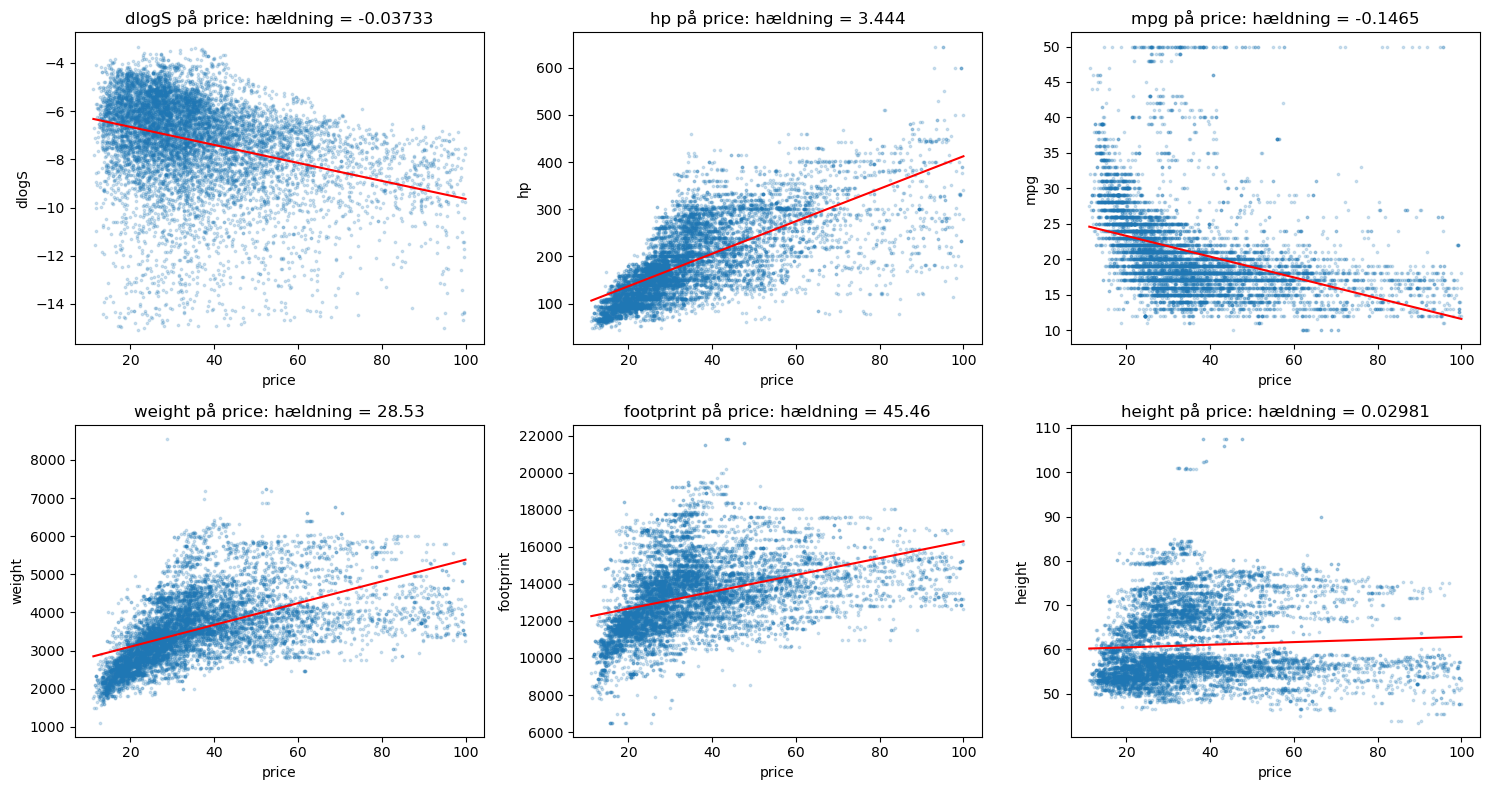

Korrelationer med pris og dlogS
              dlogS     price        hp       mpg    weight  footprint  \
dlogS      1.000000 -0.325879 -0.212328 -0.029636 -0.086062   0.054004   
price     -0.325879  1.000000  0.703196 -0.381227  0.544305   0.395439   
hp        -0.212328  0.703196  1.000000 -0.515324  0.727541   0.582349   
mpg       -0.029636 -0.381227 -0.515324  1.000000 -0.557579  -0.521406   
weight    -0.086062  0.544305  0.727541 -0.557579  1.000000   0.833413   
footprint  0.054004  0.395439  0.582349 -0.521406  0.833413   1.000000   
height     0.052683  0.060698  0.287080 -0.334672  0.712067   0.526091   

             height  
dlogS      0.052683  
price      0.060698  
hp         0.287080  
mpg       -0.334672  
weight     0.712067  
footprint  0.526091  
height     1.000000  


In [26]:
pairs = [('price', 'dlogS'), ('price','hp' ), ('price','mpg'), ('price','weight'),('price','footprint'),('price','height')]

fig, axes = plt.subplots(2,3,figsize=(15,8))
for ax, (xv,yv) in zip(axes.ravel(), pairs):
    ax.scatter(df[xv], df[yv], s=3, alpha=0.2)
    m = mlr.ols(y=df[yv],X=df[['const', xv]])
    grid = np.linspace(df[xv].min(),df[xv].max(),100)
    ax.plot(grid, m['beta_hat'][0,0] + m['beta_hat'][1,0]*grid, color='red')
    ax.set_xlabel(xv); ax.set_ylabel(yv)
    ax.set_title(f'{yv} på {xv}: hældning = {m['beta_hat'][1,0]:.4g}')
plt.tight_layout()
plt.show()

print('Korrelationer med pris og dlogS')
print(df[['dlogS','price','hp','mpg','weight','footprint','height']].corr())

### 1B
Fire OLS-specifikationer for $log(s_{jt}/s_{0t}) = dlogS$

In [27]:
y = df['dlogS']

#Variabellister
cont      = ['hp', 'mpg', 'height', 'footprint', 'weight', 'number_trims']
other     = ['releaseYear', 'yearsSinceDesign']
D_type    = ['sport', 'EV', 'truck', 'suv', 'van']
cont_log  = ['log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight', 'log_number_trims']

year_dummies = pd.get_dummies(df['year'], prefix='y', drop_first=True, dtype=int)
df = pd.concat([df, year_dummies], axis=1)
years = list(year_dummies.columns)

# Specifikation 1-4
m1 = mlr.ols(y=y, X=df[['const', 'price']])
m2 = mlr.ols(y=y, X=df[['const', 'price'] + cont + other + D_type])
m3 = mlr.ols(y=y, X=df[['const', 'price'] + cont + other + D_type + years])
m4 = mlr.ols(y=y, X=df[['const', 'price'] + cont_log + other + D_type + years])
models = [m1, m2, m3, m4]

# Fuld output (alle parametre og standardfejl, TSS/ESS/RSS og R2)
mlr.summary(models, column_titles=['Spec 1', 'Spec 2', 'Spec 3', 'Spec 4'])

                       Spec 1     Spec 2     Spec 3     Spec 4
Dependent variable    [dlogS]    [dlogS]    [dlogS]    [dlogS]
             const    -5.9072    -5.4138    -6.8066   -25.4344
                     (0.0439)   (0.2908)   (0.3177)   (1.6540)
             price    -0.0373    -0.0243    -0.0370    -0.0298
                     (0.0011)   (0.0016)   (0.0017)   (0.0014)
       releaseYear               -1.0643    -1.2272    -0.5031
                                (0.0614)   (0.0608)   (0.0542)
  yearsSinceDesign               -0.1269    -0.1278    -0.1077
                                (0.0059)   (0.0058)   (0.0050)
             sport               -0.6144    -0.6522    -0.5040
                                (0.0631)   (0.0618)   (0.0547)
                EV               -0.6321    -0.7759    -0.9254
                                (0.2060)   (0.2010)   (0.1688)
             truck               -0.1571    -0.3225    -0.6029
                                (0.0854)   (0.0835)   (

### 1C
Udfør test af $H_0 : \alpha = 0$, mod det tosidede alternativ $H_A : \alpha \neq 0$

In [28]:
r1 = mlr.ols(y=y, X=df[['const', 'price']], robust=True)
r2 = mlr.ols(y=y, X=df[['const', 'price'] + cont + other + D_type], robust=True)
r3 = mlr.ols(y=y, X=df[['const', 'price'] + cont + other + D_type + years], robust=True)
r4 = mlr.ols(y=y, X=df[['const', 'price'] + cont_log + other + D_type + years], robust=True)
robust_models = [r1, r2, r3, r4]

def alpha_test(m):
    j = m['lbl_X'].index('price')
    return m['beta_hat'][j, 0], m['se'][j, 0], m['t_stats'][j, 0], m['p_values'][j, 0]
 
rows = []
for name, m, r in zip(['Spec 1', 'Spec 2', 'Spec 3', 'Spec 4'], models, robust_models):
    a, se, t, p = alpha_test(m)
    _, se_r, t_r, p_r = alpha_test(r)
    rows.append({'Spec': name, 'alpha_hat': a,
                 'SE': se, 't': t, 'p-værdi': p,
                 'Robust SE': se_r, 'Robust t': t_r, 'Robust p': p_r})
 
test_table = pd.DataFrame(rows).set_index('Spec')
print(test_table)

frihedsgrader = m4['n'] - m4['k']          # antal observationer minus antal parametre (inkl. konstant)
t_crit = stats.t.ppf(0.975, frihedsgrader)
print(f"\nKritisk værdi (5%, tosidet), frihedsgrader = {frihedsgrader}: {t_crit:.3f}")

        alpha_hat        SE          t  p-værdi  Robust SE   Robust t  \
Spec                                                                    
Spec 1  -0.037326  0.001100 -33.934529      0.0   0.001044 -35.756000   
Spec 2  -0.024260  0.001611 -15.056687      0.0   0.001616 -15.013312   
Spec 3  -0.036958  0.001687 -21.903210      0.0   0.001694 -21.818086   
Spec 4  -0.029820  0.001422 -20.969296      0.0   0.001401 -21.281838   

        Robust p  
Spec              
Spec 1       0.0  
Spec 2       0.0  
Spec 3       0.0  
Spec 4       0.0  

Kritisk værdi (5%, tosidet), frihedsgrader = 9641: 1.960


### 2A

In [29]:
x_vars = cont_log + other + D_type
make_d = pd.get_dummies(df['make'],drop_first = True,dtype=int)
df = df.drop(columns=[c for c in make_d.columns if c in df.columns])   # fjern gamle kopier
df = pd.concat([df, make_d], axis=1)
makes = list(make_d.columns)

def coef(m, name):
    j = m['lbl_X'].index(name)
    return m['beta_hat'][j, 0], m['se'][j, 0]

In [49]:
X_dum = ['const', 'price'] + x_vars + years + makes
m_dummies = mlr.ols(y=y, X=df[X_dum])

vars_w = ['dlogS', 'price'] + x_vars + years 
df_w = df.copy()
for v in vars_w:
    df_w[v] = df[v] - df.groupby('make')[v].transform('mean')
    
X_w = ['price'] + x_vars + years
m_within = mlr.ols(y=df_w['dlogS'], X=df_w[X_w])
 
alpha_ols = coef(m_dummies, 'price')[0]
models = [m_dummies, m_within]
mlr.summary(models, column_titles=['Make-dummies', 'Within'])

                   Make-dummies     Within
Dependent variable      [dlogS]    [dlogS]
             price      -0.0337    -0.0337
                       (0.0017)   (0.0017)
            log_hp       0.3750     0.3750
                       (0.0950)   (0.0947)
           log_mpg      -0.1240    -0.1240
                       (0.1045)   (0.1041)
        log_height      -0.8707    -0.8707
                       (0.2550)   (0.2542)
     log_footprint       2.0209     2.0209
                       (0.2279)   (0.2271)
        log_weight      -0.9774    -0.9774
                       (0.2024)   (0.2017)
  log_number_trims       1.1894     1.1894
                       (0.0174)   (0.0173)
       releaseYear      -0.4066    -0.4066
                       (0.0500)   (0.0498)
  yearsSinceDesign      -0.1103    -0.1103
                       (0.0048)   (0.0047)
             sport      -0.5421    -0.5421
                       (0.0528)   (0.0526)
                EV      -0.9817    -0.9817
           

### 2C

In [31]:
def first_stage_F(endog, X1, Ze):
    """First stage: regress endog on [X1, Ze]. F-test of H0: Ze coefficients = 0."""
    m_ur = mlr.ols(y=endog, X=pd.concat([X1, Ze], axis=1))
    m_r  = mlr.ols(y=endog, X=X1)
    rss_ur = float(np.sum(m_ur['u_hat']**2))
    rss_r  = float(np.sum(m_r['u_hat']**2))
    q, n, k = Ze.shape[1], len(endog), X1.shape[1] + Ze.shape[1]
    F = ((rss_r - rss_ur) / q) / (rss_ur / (n - k))
    return m_ur, F, n - k            # model, F-statistic, residual df

X1_cols = ['const'] + x_vars + years + makes

fs, F_rxr, dof = first_stage_F(df['price'], df[X1_cols], df[['RXR']])
g1, g1_se = coef(fs, 'RXR')
t = g1 / g1_se
p = 2 * (1 - stats.t.cdf(abs(t), dof))
print(f"First stage: gamma1 = {g1:.4f}, se = {g1_se:.4f}, t = {t:.2f}, p = {p:.4f}, F = {F_rxr:.1f}")
 
m_iv_rxr = mlr.tsls(y=y, X1=df[X1_cols], X2=df[['price']], Ze=df[['RXR']])
a_iv, a_iv_se = coef(m_iv_rxr, 'price')
print(f"OLS (make-dummies): alpha = {alpha_ols:.4f}")
print(f"2SLS (RXR):         alpha = {a_iv:.4f}  (se = {a_iv_se:.4f})")

First stage: gamma1 = 4.1465, se = 0.5157, t = 8.04, p = 0.0000, F = 64.6
OLS (make-dummies): alpha = -0.0337
2SLS (RXR):         alpha = -0.1694  (se = 0.0272)


### 3A

In [32]:
gh = ['gh_log_height', 'gh_log_footprint', 'gh_log_hp', 'gh_log_mpg', 'gh_log_weight']

X2 = df[['price']]
X1 = df[X1_cols]

m_gh     = mlr.tsls(y=y, X1=X1, X2=X2, Ze=df[gh])
m_gh_rxr = mlr.tsls(y=y, X1=X1, X2=X2, Ze=df[gh + ['RXR']])

models = [m_gh, m_gh_rxr]
mlr.summary(models, column_titles=['GH-instrumenter', 'GH+RXR-instrumenter'])

                   GH-instrumenter GH+RXR-instrumenter
Dependent variable         [dlogS]             [dlogS]
             const        -12.3201            -13.4749
                          (1.8729)            (1.8610)
            log_hp          0.1268              0.2295
                          (0.1141)            (0.1129)
           log_mpg         -0.1963             -0.1664
                          (0.1064)            (0.1061)
        log_height         -0.6257             -0.7271
                          (0.2633)            (0.2623)
     log_footprint          2.1507              2.0970
                          (0.2310)            (0.2304)
        log_weight         -1.4850             -1.2750
                          (0.2403)            (0.2378)
  log_number_trims          1.2093              1.2011
                          (0.0182)            (0.0181)
       releaseYear         -0.3948             -0.3997
                          (0.0503)            (0.0502)
  yearsSin

Test for overidentifikation

In [33]:
df['gh_uhat'] = m_gh['u_hat']
df['gh_rxr_uhat'] = m_gh_rxr['u_hat']

m_gh_sargan = mlr.ols(y=df['gh_uhat'], X=pd.concat([X1, df[gh]],axis=1))
m_gh_rxr_sargan = mlr.ols(y=df['gh_rxr_uhat'], X=pd.concat([X1, df[gh + ['RXR']]],axis=1))

J_gh = m_gh_sargan['n'] * m_gh_sargan['R_squared']
J_gh_rxr = m_gh_rxr_sargan['n'] * m_gh_rxr_sargan['R_squared']

p_gh = 1 - stats.chi2.cdf(J_gh,     len(gh) - 1)
p_gh_rxr = 1 - stats.chi2.cdf(J_gh_rxr, len(gh + ['RXR']) - 1)
# - 1 ved len til sidst, fordi det er l = 1, antal endogene variable

print(f"GH: J = {J_gh:.2f} ~ chi2({len(gh) - 1}), p = {p_gh:.4f}")
print(f"GH + RXR: J = {J_gh_rxr:.2f} ~ chi2({len(gh)}), p = {p_gh_rxr:.4f}")

GH: J = 30.91 ~ chi2(4), p = 0.0000
GH + RXR: J = 80.28 ~ chi2(5), p = 0.0000


### 3B

OLS
         count      mean        std        min       50%        max
mc      9694.0  6.302114  17.143271 -18.686447  2.087541  70.275425
elast   9694.0 -1.212193   0.576811  -3.365303 -1.070259  -0.373594
markup  9694.0  0.999042   0.424653   0.297150  0.934354   2.676699
IV
         count       mean        std        min        50%        max
mc      9694.0  30.135872  17.129868   5.215940  25.907497  94.081449
elast   9694.0  -6.099203   2.902250 -16.932669  -5.385053  -1.879757
markup  9694.0   0.198556   0.084398   0.059057   0.185699   0.531984


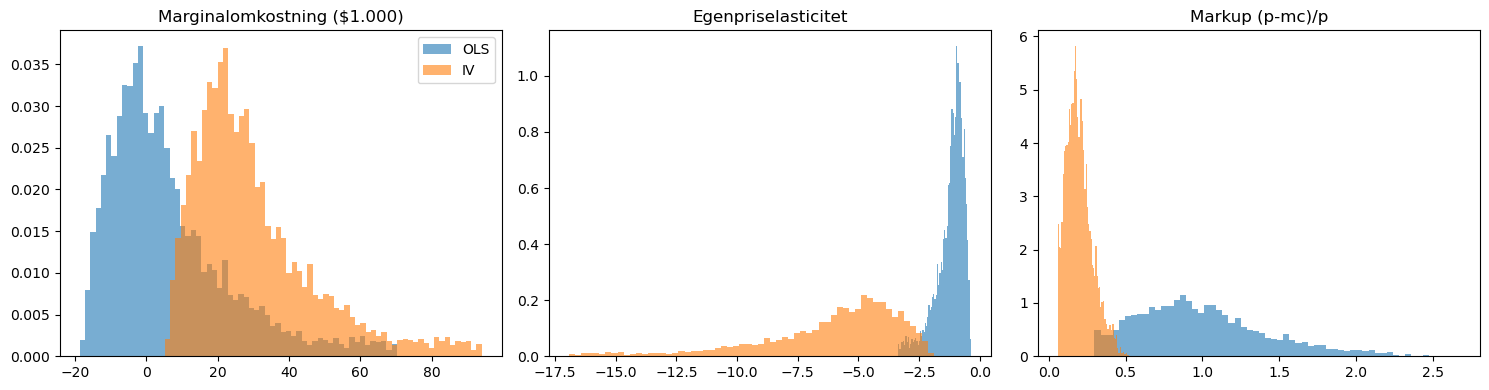

In [34]:
def structural(alpha):
    out = pd.DataFrame(index=df.index)
    out['mc'] = df['price'] - 1 / (-alpha * (1 - df['market_share']))
    out['elast'] = alpha * df['price'] * (1 - df['market_share'])
    out['markup'] = (df['price'] - out['mc']) / df['price']
    return out

alpha_ols = m_dummies['beta_hat'][1,0]
alpha_iv =  m_iv_rxr['beta_hat'][-1][0]

ols_res = structural(alpha_ols)
iv_res  = structural(alpha_iv)

print('OLS')
print(ols_res.describe(percentiles=[]).T)
print('IV')
print(iv_res.describe(percentiles=[]).T)

# Fordelinger: OLS vs IV
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (v, lab) in zip(axes, [('mc', 'Marginalomkostning ($1.000)'),
                               ('elast', 'Egenpriselasticitet'),
                               ('markup', 'Markup (p-mc)/p')]):
    ax.hist(ols_res[v], bins=60, alpha=0.6, density=True, label='OLS')
    ax.hist(iv_res[v],  bins=60, alpha=0.6, density=True, label='IV')
    ax.set_title(lab)
axes[0].legend()
plt.tight_layout()
plt.show()
 

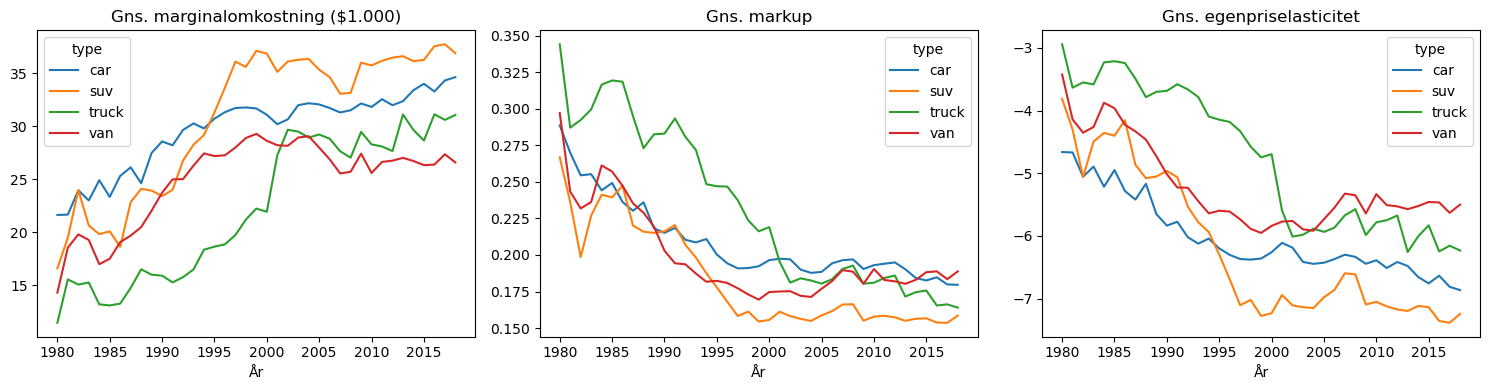

In [35]:
# Udvikling over tid pr. biltype (IV)
d = df[['year', 'type']].join(iv_res)
types = ['car', 'suv', 'truck', 'van']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (v, lab) in zip(axes, [('mc', 'Gns. marginalomkostning ($1.000)'),
                               ('markup', 'Gns. markup'),
                               ('elast', 'Gns. egenpriselasticitet')]):
    d.groupby(['year', 'type'])[v].mean().unstack()[types].plot(ax=ax)
    ax.set_title(lab); ax.set_xlabel('År')
plt.tight_layout()
plt.show()

### 3C

In [47]:
df['log_mc'] = np.log(iv_res['mc'])
 
X_mc = ['const'] + x_vars + ['RXR'] + years + makes
m_mc = mlr.ols(y=df['log_mc'], X=df[X_mc])
mlr.summary([m_mc], column_titles=['Marginalomkostningsfunktion'])

                   Marginalomkostningsfunktion
Dependent variable                    [log_mc]
             const                     -6.1842
                                      (0.2561)
            log_hp                      0.4663
                                      (0.0136)
           log_mpg                      0.1115
                                      (0.0157)
        log_height                     -0.7765
                                      (0.0382)
     log_footprint                     -0.1368
                                      (0.0342)
        log_weight                      1.3619
                                      (0.0291)
  log_number_trims                     -0.0306
                                      (0.0026)
       releaseYear                     -0.0126
                                      (0.0075)
  yearsSinceDesign                     -0.0011
                                      (0.0007)
             sport                      0.1563
             

1981    0.162
1982    0.239
1983    0.254
1984    0.225
1985    0.212
1986    0.243
1987    0.268
1988    0.241
1989    0.249
1990    0.223
1991    0.200
1992    0.201
1993    0.191
1994    0.185
1995    0.194
1996    0.187
1997    0.176
1998    0.178
1999    0.171
2000    0.140
2001    0.111
2002    0.099
2003    0.073
2004    0.042
2005   -0.003
2006   -0.051
2007   -0.118
2008   -0.153
2009   -0.112
2010   -0.119
2011   -0.154
2012   -0.161
2013   -0.157
2014   -0.142
2015   -0.119
2016   -0.114
2017   -0.123
2018   -0.130
dtype: float64


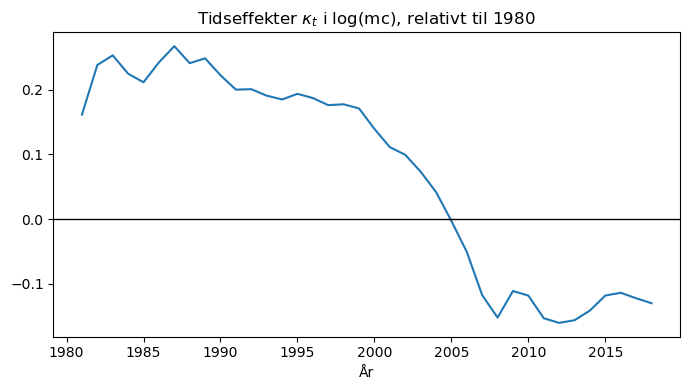

In [48]:
# Tidseffekter (kappa_t) relativt til 1980
kappa = pd.Series({y_: coef(m_mc, y_)[0] for y_ in years})
kappa.index = [int(i[2:]) for i in kappa.index]
print(kappa.round(3))

plt.figure(figsize=(7, 4))
kappa.plot()
plt.axhline(0, color='black', lw=1)
plt.title(r'Tidseffekter $\kappa_t$ i log(mc), relativt til 1980')
plt.xlabel('År')
plt.tight_layout()
plt.show()

### 4C


In [38]:
np.random.seed(2308)

In [39]:
def simulate_eq(n, beta0, beta1, gamma0, gamma1, gamma2):
    z = np.random.normal(0,1,n)
    xi = np.random.normal(0,1,n)
    nu = np.random.normal(0,1,n)
    
    diff = beta1 - gamma1
    eta0 = (gamma0 - beta0) / diff
    eta1 = gamma2 / diff
    u = (nu - xi) / diff
    
    p = eta0 + eta1 * z + u # Den reducerede ligning for prisen
    y = beta0 + beta1 * p + xi # efterspørgselslignigen
    return pd.DataFrame({'y': y, 'const': 1.0, 'p': p, 'z': z, 'xi': xi, 'nu':nu})

In [40]:
def simulate(n, r, **parametre):
    b_ols = np.empty(r)
    b_iv = np.empty(r)
    for s in range(r):
        df = simulate_eq(n, **parametre)
        b_ols[s] = mlr.ols(y=df['y'], X=df[['const', 'p']])['beta_hat'][1,0]
        b_iv[s] = mlr.tsls(y=df['y'], X1=df[['const']], X2=df[['p']],Ze=df[['z']])['beta_hat'][1,0]
    
    return b_ols, b_iv

Definere de forskellige scenearier og relevante variable til simulationen

In [41]:
n, r = 500, 500

baseline = dict(beta0 = 0.5, beta1 =-0.1, gamma0 = 0.25, gamma1=1.0, gamma2 = 1.0)

scenarier = {
    'Scenarie 1' : dict(baseline),
    'Scenarie 2' : dict(baseline, gamma2=0.25),
    'Scenarie 3' : dict(baseline, gamma1=0.25),
}

Her under kører jeg de tre scenarier, og printer bias og barians for både IV og OLS

In [42]:
rows = []
for name, parametre in scenarier.items():
    b_ols, b_iv = simulate(n,r,**parametre)
    b1 = parametre['beta1']
    rows.append({
        'Scenarie': name,
        'OLS bias': b_ols.mean() - b1,
        'OLS varians': b_ols.var(ddof=1),
        'IV bias': b_iv.mean() - b1,
        'IV varians': b_iv.var(ddof=1),
    })
    
summary = pd.DataFrame(rows).set_index('Scenarie')
print(summary)

            OLS bias  OLS varians   IV bias  IV varians
Scenarie                                               
Scenarie 1  0.367467     0.000528 -0.002642    0.002362
Scenarie 2  0.532551     0.000564 -0.024437    0.074585
Scenarie 3  0.116338     0.000049  0.000080    0.000251


Regne styrken af vores instrument ud:
$\eta_1 = \frac{\gamma_2}{\beta_1 - \gamma_1}$

In [43]:
rows = []
for name, parametre in scenarier.items():
    rows.append({
        'Scenarie': name,
        'eta1': parametre['gamma2']/(parametre['beta1']-parametre['gamma1'])
    })
summary = pd.DataFrame(rows).set_index('Scenarie')
print(summary)

                eta1
Scenarie            
Scenarie 1 -0.909091
Scenarie 2 -0.227273
Scenarie 3 -2.857143
